In [30]:
from skyfield.api import load, wgs84
from datetime import datetime
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import geopandas as gpd
import scipy.io as sio
import pytz
import copy
from scipy.optimize import minimize

In [31]:
## funcs for distance optimization 
def point_to_line_dist(x, y, m, c):
    # find the distance of point x,y from the line y = mx + c
    p2l_dist = np.abs(m*x - y + c)/np.sqrt(m**2 + 1)
    return p2l_dist

def sum_dist(point, sattrajs_coeffs):
    # find the distance of point x,y from the line y = mx + c
    x = point[0]
    y = point[1]
    dist = 0
    for line in sattrajs_coeffs:
        dist += point_to_line_dist(x, y, line[0], line[1])
    return dist

Start Time: 2024-02-20 23:19:57.051421+00:00
Len GS Centroids: 310
Len GS Centroids: 397
Len GS Centroids: 531
Len GS Centroids: 778
Len GS Centroids: 1037
Len GS Centroids: 1437
LEN GS Centroids: 1437
Possible: 31
Res:        message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 1.8350650524481824
             x: [-8.687e+01  4.261e+01]
           nit: 51
          nfev: 98
 final_simplex: (array([[-8.687e+01,  4.261e+01],
                       [-8.687e+01,  4.261e+01],
                       [-8.687e+01,  4.261e+01]]), array([ 1.835e+00,  1.835e+00,  1.835e+00])) -86.87155454612505 42.609985001442325
centrois of group  [ 42.6399028  -87.93253825]
sats in group: ['STARLINK-2422', 'STARLINK-5339', 'STARLINK-5339', 'STARLINK-30304', 'STARLINK-2404', 'STARLINK-30109', 'STARLINK-30411']
Res:        message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 1.5314864575555476
             x: [-7.566

/tmp/ipykernel_1313606/1838883142.py:78: FutureWarning: The geopandas.dataset module is deprecated and will be removed in GeoPandas 1.0. You can get the original 'naturalearth_lowres' data from https://www.naturalearthdata.com/downloads/110m-cultural-vectors/.
  world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))


Res:        message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 0.8926034832670169
             x: [-1.048e+02  4.169e+01]
           nit: 43
          nfev: 80
 final_simplex: (array([[-1.048e+02,  4.169e+01],
                       [-1.048e+02,  4.169e+01],
                       [-1.048e+02,  4.169e+01]]), array([ 8.926e-01,  8.926e-01,  8.926e-01])) -104.79713209939362 41.69173211981516
centrois of group  [  41.76059376 -104.13829363]
sats in group: ['STARLINK-2240', 'STARLINK-31118', 'STARLINK-30163', 'STARLINK-31167', 'STARLINK-6267', 'STARLINK-31070', 'STARLINK-31151']
Res:        message: Optimization terminated successfully.
       success: True
        status: 0
           fun: 2.011878059364686
             x: [-7.429e+01  4.222e+01]
           nit: 50
          nfev: 98
 final_simplex: (array([[-7.429e+01,  4.222e+01],
                       [-7.429e+01,  4.222e+01],
                       [-7.429e+01,  4.222e+01]]), array([

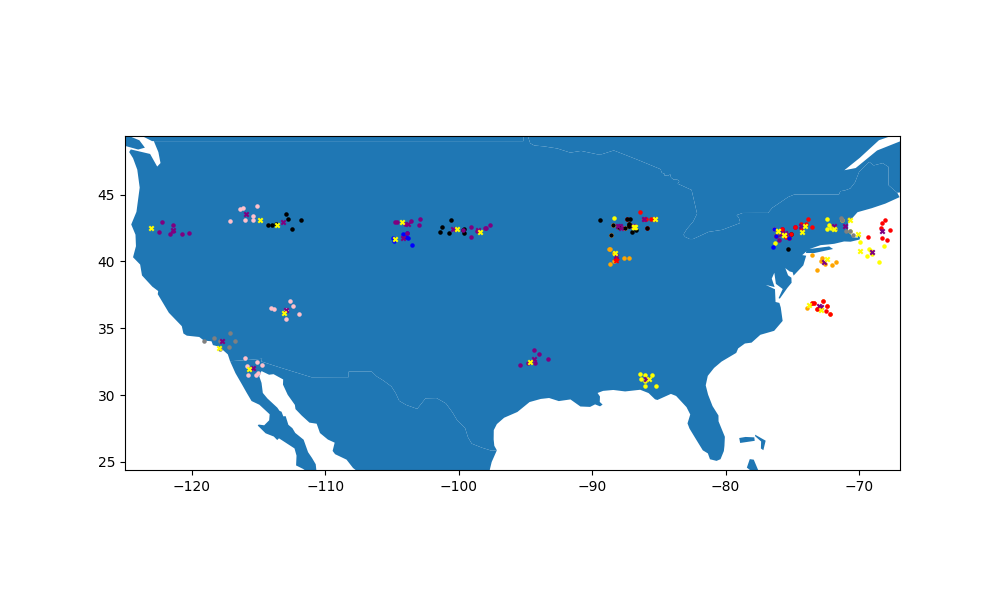

In [32]:
file_path = '/home/ishani/LeoPNT/USRP_data/2_20/utctime_20Feb2024_23_19_57_freq_11_325G_bw_2.0M_ts_1708471197.0514207_inrx0.dat'
ts = load.timescale()
satellites = load.tle_file('/home/ishani/LeoPNT/starlink_ofdm/Starloc/20Feb2024_23_19/Starlink.tle')
start_time = datetime.fromtimestamp(float(file_path.split('_')[-2]), tz=pytz.utc)
print('Start Time:', start_time)
# load sat_dopp_dict from phase_comp.mat
mat = sio.loadmat('/home/ishani/LeoPNT/starlink_ofdm/Starloc/20Feb2024_23_19/phase_comp.mat')
tracked_peaks = mat['dopp_track_dict'][0]
time_arr = []
for arr in tracked_peaks:
    time = np.median(np.real(arr[:,0]))
    time_arr.append(time)
## time_arr.append(580.0)
# sort time_arr
time_arr = sorted(time_arr)
# print('Time Arr:', time_arr)
# time_arr = [210.39600049999999, 253.6900005, 305.07300050000003, 285.54400050000004, 341.0160005, 660.8060005, 808.7960005]
time_arr = sorted(time_arr)
time_arr = np.array(time_arr)
sat_visible_time_arr = ts.utc(start_time.year, start_time.month, start_time.day, 
        start_time.hour, start_time.minute, start_time.second+start_time.microsecond/1e6+time_arr)
gs_superset = []
sat_superset = []
for time in sat_visible_time_arr:
    # print('Time:', time.utc_datetime())
    gs = []
    sat_ = []
    for sat in satellites:
        geocentric = sat.at(time)
        lat, lon = wgs84.latlon_of(geocentric)
        if lat.degrees > 24.396308 and lat.degrees < 49.384358 and lon.degrees > -125.0 and lon.degrees < -66.93457: # setting boundaries for USA
            gs.append([lat.degrees, lon.degrees])
            sat_.append(sat)
    gs_superset.append(gs)
    sat_superset.append(sat_)
    
# get number of ground stations in the superset
# print('GS Superset:', len(gs_superset[0])+len(gs_superset[1])+len(gs_superset[2])+len(gs_superset[3])+len(gs_superset[4])+len(gs_superset[5])+len(gs_superset[6])+len(gs_superset[7]))
# only get points that are close enough in consecutive time stamps
gs_subset_ = gs_superset[0]
sat_set_0 = sat_superset[0]
gs_centroids = [[[gs_subset_[i][0], gs_subset_[i][1]]] for i in range(len(gs_subset_))]
sat_init_groups = [[sat_set_0[i]] for i in range(len(sat_set_0))]

## only append points at minimum distance to the centroid    
for subset_idx,gs_subset in enumerate(gs_superset[1:]):
    gs_subset = np.array(gs_subset)
    # print('GS Subset:', gs_subset.shape)
    gs_centroids_ = copy.deepcopy(gs_centroids)
    for i,point in enumerate(gs_centroids):
        # get distance of each point in gs from the current point in gs_init_centroids
        point = np.array(point)
        point = np.mean(point, axis=0) #centroid of elements in point
        # print('Point:', point.shape)
        lat1 = np.deg2rad(point[0])
        lon1 = np.deg2rad(point[1])
        lat2 = np.deg2rad(gs_subset[:,0])
        lon2 = np.deg2rad(gs_subset[:,1])
        dist = np.arccos(np.sin(lat1)*np.sin(lat2)+np.cos(lat1)*np.cos(lat2)*np.cos(lon2-lon1))*6371
        # print('Dist:', dist.shape)
        # get the minimum distance
        min_dist, min_dist_idx = np.min(dist), np.argmin(dist)
        # print('Min Dist:', min_dist, "Point", point, "Coordinates:", gs_subset[min_dist_idx])
        # if the minimum distance is less than 100 km, add the point to the current centroid, else add the point as a new centroid
        if min_dist < 140:
            gs_centroids_[i].append([gs_subset[min_dist_idx][0], gs_subset[min_dist_idx][1]])
            sat_init_groups[i].append(sat_superset[subset_idx+1][min_dist_idx])
        else:
            gs_centroids_.append([[gs_subset[min_dist_idx][0], gs_subset[min_dist_idx][1]]])
            sat_init_groups.append([sat_superset[subset_idx+1][min_dist_idx]])

    gs_centroids = copy.deepcopy(gs_centroids_)
    print('Len GS Centroids:', len(gs_centroids))
## only append points at minimum distance to the centroid    


%matplotlib widget
world = gpd.read_file(gpd.datasets.get_path('naturalearth_lowres'))
fig, ax = plt.subplots(1, 1, figsize=(10, 6))
world.plot(ax=ax)
ax.set_xlim([-125.0, -66.93457])
ax.set_ylim([24.396308, 49.384358])
color = ['red', 'blue', 'grey', 'yellow', 'orange', 'purple', 'pink', 'black']
possible = 0
remove_set = []  
coarse_gs = []
print('LEN GS Centroids:', len(gs_centroids))
for i,sets in enumerate(gs_centroids):
    if len(sets) < len(time_arr):
        remove_set.append(i)
        continue
    # print(i, 'Sets:', len(sets))
    possible += 1
    sets = np.array(sets)
    ax.scatter(sets[:,1], sets[:,0], c=color[int(i%len(color))], s=5)
    # also plot the centroid
    centroid = np.mean(sets, axis=0)
    coarse_gs.append(centroid)
    ax.scatter(centroid[1], centroid[0], c='purple', marker='x', s=10)
ax.scatter(-88.20952606201173, 40.07216262817384, c='red', marker='*',s=15)
print('Possible:', possible)
# remove the sets that are not possible
gs_centroids = [gs_centroids[i] for i in range(len(gs_centroids)) if i not in remove_set]
sat_init_groups = [sat_init_groups[i] for i in range(len(sat_init_groups)) if i not in remove_set]

# satellite trajectory lines
for gp_idx,group in enumerate(sat_init_groups):
    lines_coeffs = []
    sats_name_arr = []
    for i,sat in enumerate(group):
        sats_name_arr.append(sat.name)
        # get satellite subpoints around 10 seconds of the time of highest elevation at 0.1 sec steps
        time_of_highest_elevation = sat_visible_time_arr[i].utc_datetime()
        span = np.arange(-5, 5, 0.1)
        single_sat_time_arr = ts.utc(time_of_highest_elevation.year, time_of_highest_elevation.month, time_of_highest_elevation.day, 
            time_of_highest_elevation.hour, time_of_highest_elevation.minute, time_of_highest_elevation.second+time_of_highest_elevation.microsecond/1e6+span)
        subpoints = wgs84.latlon_of(sat.at(single_sat_time_arr))
        x = subpoints[1].degrees # longitudes
        y = subpoints[0].degrees # latitudes
        # plt.plot(x, y, '--', color='black')
        # plt.text(x[-1], y[-1], sat.name, fontsize=5, color='black')
        # polyfit line to x,y
        sat_traj_line = np.polyfit(x, y, 1)
        # print('Satellite Trajectory Line slope:', sat_traj_line[0], "Intercept:", sat_traj_line[1])
        # find a point on earth that minimizes the distance to the satellite trajectory lines
        lines_coeffs.append(sat_traj_line)
    #minimize distance to the lines
    start_point = np.mean(gs_centroids[gp_idx], axis=0)
    res = minimize(sum_dist, [start_point[1]-1, start_point[0]-1], args=(lines_coeffs), method = 'Nelder-Mead')
    print('Res:', res, res.x[0], res.x[1])
    print("centrois of group ", start_point)
    #plot the point
    ax.scatter(res.x[0], res.x[1], c='yellow', marker='x', s=10)
    print('sats in group:', sats_name_arr)
plt.show()
     
       

In [1]:
# speeding up simualtion

from sat_id import doppler_sim, faster_doppler_sim
import scipy.io as sio
iq0_path ='/home/ishani/LeoPNT/USRP_data/2_20/utctime_20Feb2024_23_19_57_freq_11_325G_bw_2.0M_ts_1708471197.0514207_inrx0.dat'
iq1_path = iq0_path.replace('inrx0', 'inrx1')
iq2_path = iq0_path.replace('inrx0', 'inrx2')
# date = iq0_path.split('_')[-10]+'_'+iq0_path.split('_')[-9].replace(":","-")
date = iq0_path.split('_')[-12]+'_'+iq0_path.split('_')[-11]+'_'+iq0_path.split('_')[-10]
start_time = float(iq0_path.split('_')[-2])
fc = 11.325e9
tx_freq = 11.3251e9
sample_rate = 2e6

sim_start_time = start_time
t_end = sio.loadmat(date + '/info.mat')['t_end'][0][0]
sim_end_time = sim_start_time+t_end
sat_dopp_dict, t_list = faster_doppler_sim(date, date+'/Starlink.tle', fc, sim_start_time, sim_end_time, 1)

output_doppler_file = date+"/output_doppler_farm.mat"
output = {}
sio.savemat(output_doppler_file, {'sat_dopp_dict': sat_dopp_dict, 't_list': t_list})

number of Starlink satellites loaded 5448
Duration in secs:  880.434240102768
Number of visible satellites:  32
